In [1]:
import bayesbay as bb
from bayesbay.discretization import Voronoi1D
import numpy as np
import matplotlib.pyplot as plt
from ComplyBay.forward.ncomp_fortran import ncomp_fortran_batch
np.random.seed(30)

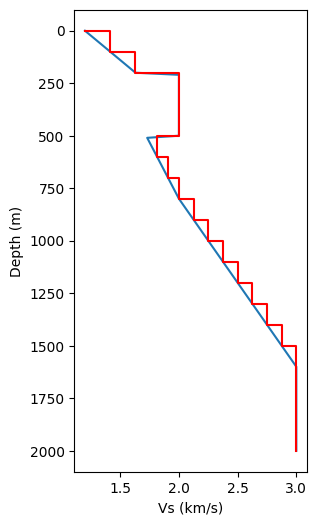

In [2]:
d = [0, 200, 210, 500, 510, 800, 1200, 1600, 2000]
vs_d = [1.20, 1.63, 2.00, 2.00, 1.73, 2.0, 2.5, 3.0, 3.0]
d_new = np.linspace(0, 1000, 11).tolist() + np.linspace(1000, 2000, 11).tolist()
vs_new = np.interp(d_new, d, vs_d)

fig, ax = plt.subplots(figsize=(3, 6))
ax.plot(vs_d, d)
ax.step(vs_new, d_new, where='post', color='red', label='Interpolated')
ax.set_xlabel('Vs (km/s)')
ax.set_ylabel('Depth (m)')
ax.invert_yaxis()


In [3]:
THICKNESS = np.diff(np.array(d_new), prepend=0)
VS = np.array(vs_new)
VP = 1.78 * VS
RHO = np.full_like(VS, 2.0)

THICKNESS = THICKNESS[1:]
VS = VS[1:]
VP = VP[1:]
RHO = RHO[1:]


water_depth = 780
freqs = np.geomspace(0.005, 0.05, 50)
# freqs = np.linspace(0.005, 0.05, 50)

print(np.vstack([THICKNESS, VS, VP, RHO]).T)

[[100.           1.415        2.5187       2.        ]
 [100.           1.63         2.9014       2.        ]
 [100.           2.           3.56         2.        ]
 [100.           2.           3.56         2.        ]
 [100.           2.           3.56         2.        ]
 [100.           1.8137931    3.22855172   2.        ]
 [100.           1.90689655   3.39427586   2.        ]
 [100.           2.           3.56         2.        ]
 [100.           2.125        3.7825       2.        ]
 [100.           2.25         4.005        2.        ]
 [  0.           2.25         4.005        2.        ]
 [100.           2.375        4.2275       2.        ]
 [100.           2.5          4.45         2.        ]
 [100.           2.625        4.6725       2.        ]
 [100.           2.75         4.895        2.        ]
 [100.           2.875        5.1175       2.        ]
 [100.           3.           5.34         2.        ]
 [100.           3.           5.34         2.        ]
 [100.    

In [4]:
def initialize_vs(param, positions=None):
    vmin, vmax = param.get_vmin_vmax(positions)
    sorted_vals = np.sort(np.random.uniform(vmin, vmax, positions.size))
    return sorted_vals

vs = bb.prior.UniformPrior(name="vs", 
                           vmin=np.array(vs_d) - 1.00,
                           vmax=np.array(vs_d) + 1.00,
                           position=d,
                           perturb_std=0.15)
vs.set_custom_initialize(initialize_vs)

In [5]:
# [thickness (in m), rho (in g/cm3), vp (in km/s), vs (in km/s)]
vel_model = np.array([THICKNESS, RHO, VP, VS]).T
ncomp = ncomp_fortran_batch(water_depth, freqs, vel_model, log_scale=True)
# d_obs = ncomp * (1 + np.random.normal(0, COMPLY_STD, ncomp.shape))
COMPLY_STD = 0.01
noise = np.random.normal(0, COMPLY_STD, ncomp.shape)
d_obs = ncomp + noise

# print(vel_model)

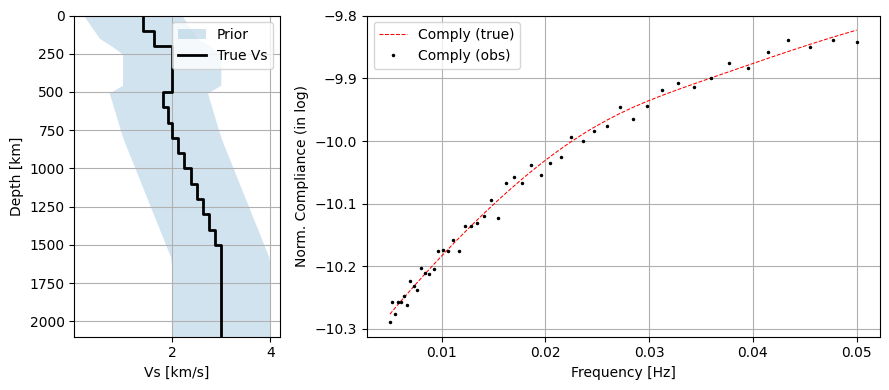

In [6]:
depth_prior = np.linspace(0, 2500)
vmin_prior, vmax_prior = vs.get_vmin_vmax(depth_prior)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 4), gridspec_kw={'width_ratios': [1, 2.5]})
ax1.fill_betweenx(depth_prior, vmin_prior, vmax_prior, alpha=0.2, label='Prior')
Voronoi1D.plot_tessellation(THICKNESS, 
                            VS, 
                            label='True Vs', 
                            ax=ax1, 
                            color='k', 
                            lw=2, 
                            input_type='extents')
ax1.set_xlabel('Vs [km/s]')
ax1.set_ylabel('Depth [km]')
ax1.set_ylim(np.cumsum(THICKNESS)[-1] + max(THICKNESS), 0)
ax1.grid()
ax1.legend()

ax2.plot(freqs, ncomp, 'r--', label="Comply (true)", lw=0.75)
ax2.plot(freqs, d_obs, 'k.', label="Comply (obs)", markersize=3)
# ax2.semilogx(freqs, ncomp, 'r--', label="Comply (true)", lw=0.75)
# ax2.semilogx(freqs, d_obs, 'k.', label="Comply (obs)", markersize=3)
ax2.set_xlabel('Frequency [Hz]')
ax2.set_ylabel('Norm. Compliance (in log)')
ax2.grid()
ax2.legend()
fig.tight_layout()

In [7]:
voronoi = Voronoi1D(
    name="voronoi", 
    vmin=0,
    vmax=2500,
    perturb_std=10,
    n_dimensions=None, 
    n_dimensions_min=10,
    n_dimensions_max=24,
    parameters=[vs], 
    birth_from='neighbour'
)
parameterization = bb.parameterization.Parameterization(voronoi)

In [8]:
def forward_sw(state):
    voronoi = state["voronoi"]
    voronoi_sites = voronoi["discretization"]
    thickness = Voronoi1D.compute_cell_extents(voronoi_sites)
    vs = voronoi["vs"]
    vp = 1.78 * vs
    rho = np.full_like(vs, 2.0)
    vel_model = np.array([thickness, rho, vp, vs]).T
    # water_depth = 780
    # freqs = np.linspace(0.005, 0.05, 50)
    d_pred = ncomp_fortran_batch(water_depth, freqs, vel_model, log_scale=True)
    return d_pred

In [9]:
from bayesbay.likelihood import Target

d_obs_min = np.min(d_obs)
d_obs_max = np.max(d_obs)
d_obs_mean = np.mean(d_obs)
print(d_obs_min, d_obs_max, d_obs_mean)

target = Target("Comply", 
                d_obs, 
#                 covariance_mat_inv = 1 / noise**2
# )
                   std_min=0.001,
                   std_max=0.02,
                   std_perturb_std=0.001)

-10.289327532462998 -9.837878017238214 -10.074948399839773


In [10]:
from bayesbay.likelihood import LogLikelihood
log_likelihood = LogLikelihood(targets=target, fwd_functions=forward_sw)

inversion = bb.BayesianInversion(
    parameterization=parameterization, 
    log_likelihood=log_likelihood,
    n_chains=24
)


In [11]:
inversion.run(
    sampler=None, 
    n_iterations=350_000, 
    burnin_iterations=100_000, 
    save_every=150,
    verbose=False
)

In [12]:
for chain in inversion.chains:
    chain.print_statistics()

Chain ID: 0
TEMPERATURE: 1
EXPLORED MODELS: 350000
ACCEPTANCE RATE: 190253/350000 (54.36 %)
PARTIAL ACCEPTANCE RATES:
	NoisePerturbation(Comply): 37202/50126 (74.22%)
	ParamSpacePerturbation(param_space_name=voronoi):
		BirthPerturbation(voronoi): 8940.00/49674.00 (18.00%)
		DeathPerturbation(voronoi): 8934.00/50127.00 (17.82%)
		ParamPerturbation(voronoi.discretization): 45190.00/50183.00 (90.05%)
		ParamPerturbation(voronoi.vs): 89987.00/149890.00 (60.04%)
Chain ID: 1
TEMPERATURE: 1
EXPLORED MODELS: 350000
ACCEPTANCE RATE: 187891/350000 (53.68 %)
PARTIAL ACCEPTANCE RATES:
	NoisePerturbation(Comply): 37420/50246 (74.47%)
	ParamSpacePerturbation(param_space_name=voronoi):
		BirthPerturbation(voronoi): 9023.00/50264.00 (17.95%)
		DeathPerturbation(voronoi): 9012.00/49988.00 (18.03%)
		ParamPerturbation(voronoi.discretization): 44192.00/49938.00 (88.49%)
		ParamPerturbation(voronoi.vs): 88244.00/149564.00 (59.00%)
Chain ID: 2
TEMPERATURE: 1
EXPLORED MODELS: 350000
ACCEPTANCE RATE: 189171

dict_keys(['mean', 'median', 'std', 'percentiles'])


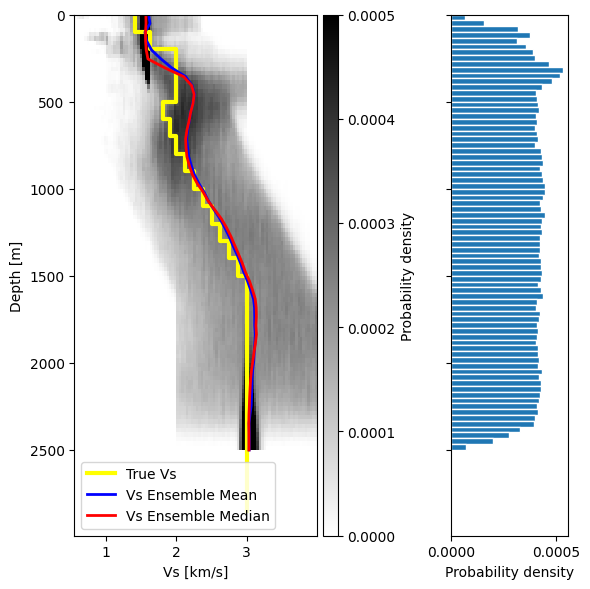

In [13]:
results = inversion.get_results(concatenate_chains=True)

sampled_voronoi_nuclei = results['voronoi.discretization']
sampled_thickness = [Voronoi1D.compute_cell_extents(n) for n in sampled_voronoi_nuclei]
sampled_vs = results['voronoi.vs']

# print(sampled_vs)
# print(sampled_thickness)
interp_depths = np.linspace(0, 2500)
statistics_vs = Voronoi1D.get_tessellation_statistics(
    sampled_thickness, sampled_vs, interp_depths, input_type='extents'
    )
print(statistics_vs.keys())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6, 6), gridspec_kw={'width_ratios': [2.5, 1]})
ax1, cbar = Voronoi1D.plot_tessellation_density(sampled_thickness, 
                                                sampled_vs, 
                                                input_type='extents', 
                                                ax=ax1, 
                                                cmap='binary', 
                                                vmin=0, 
                                                vmax=0.0005
)
# cbar.set_label('Density', rotation=270, labelpad=15)
Voronoi1D.plot_tessellation(THICKNESS, 
                            VS, 
                            ax=ax1, 
                            color='yellow', 
                            lw=3, 
                            label='True Vs',
                            input_type='extents')
ax1.plot(statistics_vs['mean'], interp_depths, 'b', lw=2, label='Vs Ensemble Mean')
ax1.plot(statistics_vs['median'], interp_depths, 'r', lw=2, label='Vs Ensemble Median')
ax1.set_xlabel("Vs [km/s]")
ax1.set_ylabel("Depth [m]")
ax1.legend()

Voronoi1D.plot_interface_hist(sampled_voronoi_nuclei, bins=75, ec='w', ax=ax2)
ax2.tick_params(labelleft=False)
ax2.set_ylabel('')
ax2.set_ylim(*ax1.get_ylim())
plt.tight_layout()
plt.show()

dict_keys(['voronoi.n_dimensions', 'voronoi.discretization', 'voronoi.vs', 'Comply.std', 'Comply.dpred'])


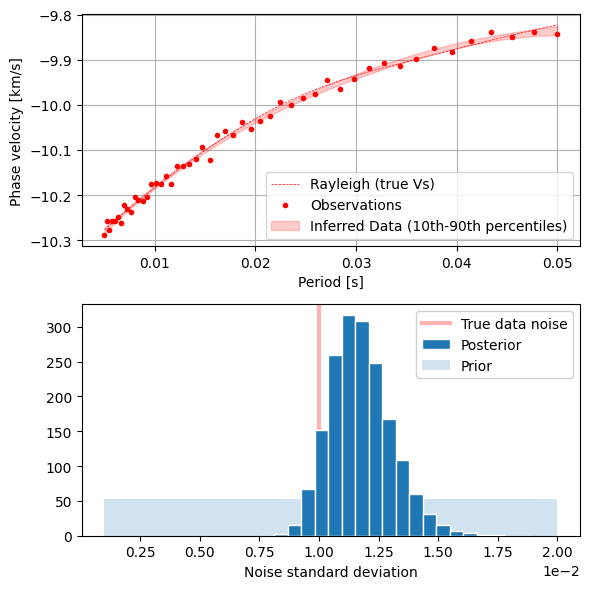

In [14]:
print(results.keys())

d_pred = np.array(results['Comply.dpred'])
percentiles = np.percentile(d_pred, (10, 90), axis=0)

# Predicted dispersion curves
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 6))
ax1.plot(freqs, ncomp, 'r--', label='Rayleigh (true Vs)', lw=0.5)
ax1.plot(freqs, d_obs, 'ro', label='Observations', markersize=3)
ax1.fill_between(freqs, percentiles[0], percentiles[1], color='r', alpha=0.2, label='Inferred Data (10th-90th percentiles)', zorder=100)
ax1.set_xlabel('Period [s]')
ax1.set_ylabel('Phase velocity [km/s]')
ax1.grid()
ax1.legend()

# Histogram of inferred data noise
ax2.axvline(x=COMPLY_STD, color='r', lw=3, alpha=0.3, label='True data noise')
# ax2.axvline(x=COMPLY_STD * 1e-10, color='r', lw=3, alpha=0.3, label='True data noise')

pdf, bins, _ = ax2.hist(results['Comply.std'], density=True, bins=20, ec='w', zorder=100, label='Posterior')
ax2.fill_between([target.std_min, target.std_max], 1 / (target.std_max - target.std_min), alpha=0.2, label='Prior')
ax2.set_xlabel('Noise standard deviation')
ax2.ticklabel_format(style='sci', axis='x', scilimits=(0,0))
ax2.legend(framealpha=0.9)
plt.tight_layout()
plt.show()

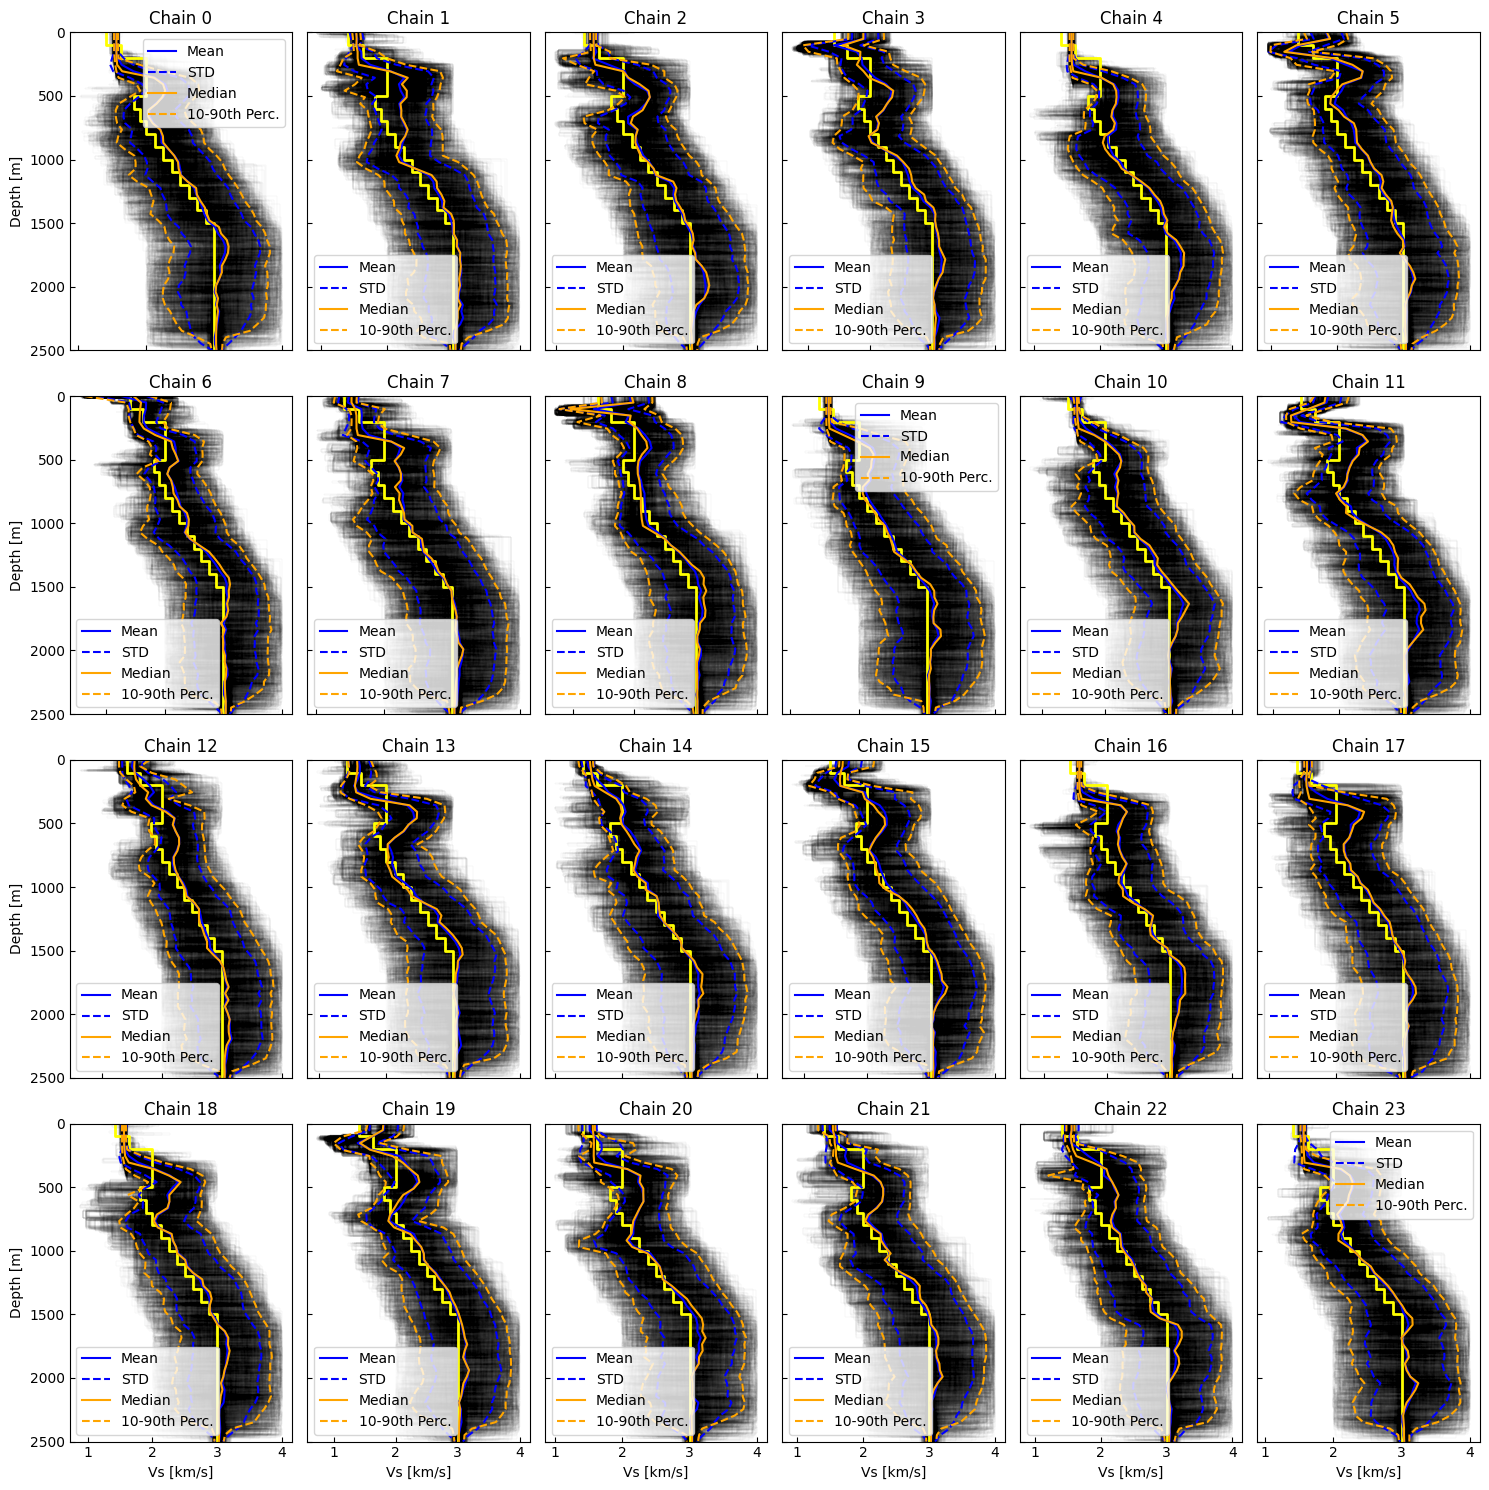

In [15]:
def get_subplot_layout(n_subplots):
    rows = int(np.sqrt(n_subplots))
    cols = int(np.ceil(n_subplots / rows))
    return rows, cols

rows, cols = get_subplot_layout(len(inversion.chains))
fig, axes = plt.subplots(rows, cols, figsize=(15, 15))
for ipanel, (ax, chain) in enumerate(zip(np.ravel(axes), inversion.chains)):
    saved_states = chain.saved_states
    saved_nuclei = saved_states["voronoi.discretization"]
    saved_vs = saved_states['voronoi.vs']
    
    Voronoi1D.plot_tessellations(saved_nuclei,
                                 saved_vs, 
                                 ax=ax, 
                                 linewidth=0.1, 
                                 color="k", 
                                 bounds=(0, 2500))
    Voronoi1D.plot_tessellation(THICKNESS, 
                                VS, 
                                color='yellow', 
                                lw=2, 
                                ax=ax,
                                input_type='extents')
    Voronoi1D.plot_tessellation_statistics(
        saved_nuclei, saved_vs, interp_depths, ax=ax
    )
    
    ax.set_title(f'Chain {chain.id}')
    ax.tick_params(direction='in', labelleft=False, labelbottom=False)
    ax.set_xlabel('')
    ax.set_ylabel('')
    
    if not ipanel % cols:
        ax.set_ylabel('Depth [m]')
        ax.tick_params(labelleft=True)
    if ipanel >= (rows-1) * cols:
        ax.set_xlabel('Vs [km/s]')
        ax.tick_params(labelbottom=True)
    
plt.tight_layout()
plt.show()